# Select Random Points and Plot

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon, box
import matplotlib.patches as mpatches
import numpy as np
import matplotlib.pyplot as plt
import time

## Read GLANCE Points for each biome

In [ ]:
# read geodataframe from file
gdf_biomeA_glance = gpd.read_parquet('../Glance_data/biomeA_glance.parquet')   
gdf_biomeB_glance = gpd.read_parquet('../Glance_data/biomeB_glance.parquet')   
gdf_biomeC_glance = gpd.read_parquet('../Glance_data/biomeC_glance.parquet')   
gdf_biomeD_glance = gpd.read_parquet('../Glance_data/biomeD_glance.parquet')  
gdf_biomeE_glance = gpd.read_parquet('../Glance_data/biomeE_glance.parquet')  
gdf_biomeF_glance = gpd.read_parquet('../Glance_data/biomeF_glance.parquet')  

In [ ]:
class_names = ['Water(0)','Developed(1)','Barren(2)','Trees(3)','Shrub(4)','Grassland(5)','Agriculture(6)'] 

## Read Biome shapefiles

In [2]:
gdf_biomeA = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeA.parquet')    # A - Tropical and Subtropical Dry Broadleaf Forests 
gdf_biomeB = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeB.parquet')    # B - Tropical and Subtropical Grasslands, Savannas, and Shrublands 
gdf_biomeC = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeC.parquet')    # C - Temparate Grasslands, Savannas, and Shrublands 
gdf_biomeD = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeD.parquet')   # D - Montane Grasslands and Shrublands 
gdf_biomeE = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeE.parquet')   # E - Mediterranean Forests, Woodlands, and Scrub 
gdf_biomeF = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/BiomeF.parquet')   # F - Deserts and Xeric Shrublands 

In [3]:
# merge biomes
gdf_all_biomes = gpd.GeoDataFrame(
    pd.concat([gdf_biomeA, gdf_biomeB, gdf_biomeC, gdf_biomeD, gdf_biomeE, gdf_biomeF], ignore_index=True),
    crs=gdf_biomeA.crs)

In [ ]:
len(gdf_all_biomes)

In [ ]:
gdf_all_biomes = gdf_all_biomes.dissolve()  # merges all polygons, removes internal boundaries, returns one row

In [ ]:
len(gdf_all_biomes)

In [ ]:
gdf_all_biomes.to_parquet('../WWF_TEOW/Biome_Shapefiles/Biomes_All_Dissolved.parquet')

In [4]:
gdf_all_biomes = gpd.read_parquet('../WWF_TEOW/Biome_Shapefiles/Biomes_All_Dissolved.parquet')

In [11]:
# Load a world map from a local file
gdf_world_10m = gpd.read_parquet("../Shapefiles/ne_10m_land.parquet")     # geodataframe. land outline from Natural Earth
gdf_world_110m = gpd.read_parquet("../Shapefiles/ne_110m_land.parquet")   # geodataframe. land outline from Natural Earth

## Clip Biome to Box

In [25]:
# western usa lon,lat,lon,lat
clip_box = box(-125, 28, -95, 49)  
gdf_biome_clipped = gpd.clip(gdf_all_biomes, clip_box)
len(gdf_biome_clipped)

1

In [ ]:
# southern africa lon,lat,lon,lat
clip_box = box(10, -40, 40, -20)  
gdf_biome_clipped = gpd.clip(gdf_all_biomes, clip_box)
len(gdf_biome_clipped)

In [ ]:
# eastern sahel lon,lat,lon,lat
clip_box = box(10, 5, 35, 25)  
gdf_biome_clipped = gpd.clip(gdf_all_biomes, clip_box)
len(gdf_biome_clipped)

In [26]:
# save clipped biome polygon
gdf_biome_clipped.to_parquet('../WWF_TEOW/biomeAll_western_usa.parquet')

In [27]:
# load clipped biome polygon
#gdf_loaded = gpd.read_parquet('../WWF_TEOW/biomeAll_southern_africa.parquet')
#gdf_loaded = gpd.read_parquet('../WWF_TEOW/biomeAll_eastern_sahel.parquet')
gdf_loaded = gpd.read_parquet('../WWF_TEOW/biomeAll_western_usa.parquet')
len(gdf_loaded)

1

In [28]:
gdf_biome_clipped = gdf_loaded.copy()

In [ ]:
plot_name = "../Inference_Change/biomeAll_southern_africa_random_points_plot.jpg"

In [13]:
gdf_countries = gpd.read_parquet('../Shapefiles/ne_10m_admin_0_countries.parquet')

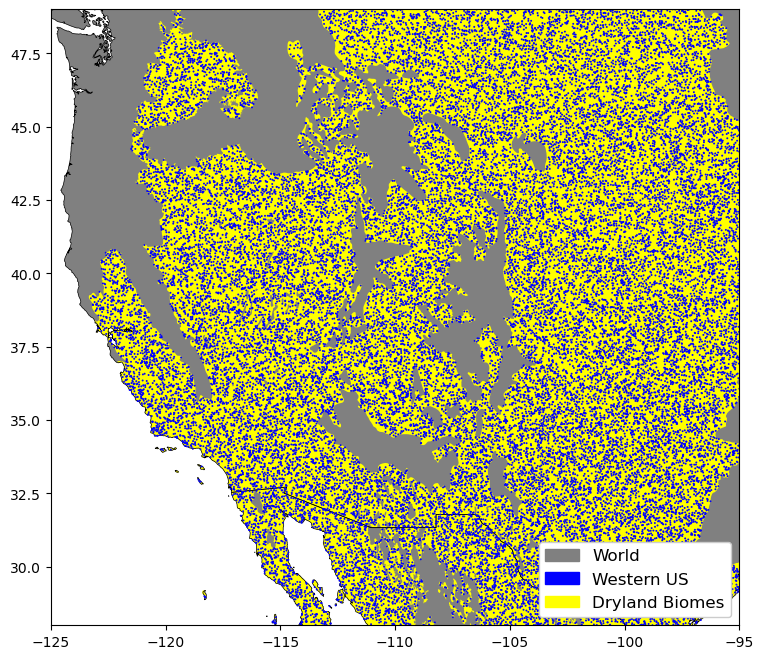

In [77]:
fig, ax = plt.subplots(figsize=(10, 8))

# world
ax.set_xlim([-160, 160])
ax.set_ylim([-80, 80])

# usa only
ax.set_xlim([-125, -95])
ax.set_ylim([28, 49])

# southern africa only
#ax.set_xlim([12, 37])
#ax.set_ylim([-35, -20])

# eastern Sahel
#ax.set_xlim([10, 35])
#ax.set_ylim([5, 25])

# eastern Sahel
#ax.set_xlim([5, 40])
#ax.set_ylim([0, 30])

# Remove tick marks and labels
#ax.set_xticks([])
#ax.set_yticks([])
#ax.set_xticklabels([])
#ax.set_yticklabels([])

gdf_countries.plot(ax=ax, color= 'grey', edgecolor='none',linewidth=0.5)

gdf_all_biomes.plot(ax=ax, color='yellow', edgecolor='none')
#gdf_biome_clipped.plot(ax=ax, color='blue', edgecolor='none')
#gdf_biomeB.plot(ax=ax, color='orange', edgecolor='grey')
#gdf_biomeD.plot(ax=ax, color='pink', edgecolor='grey')
#gdf_biomeE.plot(ax=ax, color='red', edgecolor='grey')
#gdf_biomeF.plot(ax=ax, color='yellow', edgecolor='grey')
gdf_countries.plot(ax=ax, color= 'none', edgecolor='black',linewidth=0.5)
points_gdf_4326.plot(ax=ax, markersize=2, color='blue', edgecolor='none')   # points just created

# Create custom legend handles
grey_patch = mpatches.Patch(color="grey", label="World")
blue_patch = mpatches.Patch(color="blue", label="Western US")
yellow_patch = mpatches.Patch(color="yellow", label="Dryland Biomes")

ax.legend(handles=[grey_patch, blue_patch, yellow_patch], loc="lower right",fontsize=12,frameon=True,framealpha=1.0 )

#plt.savefig(plot_name, dpi=300, bbox_inches="tight")
plt.show()

## Reproject Polygon and Explode

In [44]:
gdf_projected = gdf_biome_clipped.to_crs(epsg=6933)   # epsg6933 is a global equal area projection
print(len(gdf_projected))
print(gdf_projected.crs)

1
EPSG:6933


In [45]:
# each polygon is separate gdf row
gdf_exploded = gdf_projected.explode(index_parts=True).reset_index(drop=True)

# Now each row is one single polygon
print(f"Original rows: {len(gdf_projected)}")
print(f"After exploding: {len(gdf_exploded)}")

Original rows: 1
After exploding: 34


In [46]:
gdf_exploded = gdf_exploded.dissolve()
print(f"After dissolving: {len(gdf_exploded)}")

After dissolving: 1


In [47]:
# calculate area for each polygon and add a new column
gdf_exploded["area_km2"] = ( gdf_exploded.geometry.area / 1_000_000).round(2)

In [48]:
gdf_exploded["area_km2"]    # print polygon areas

0    4025850.31
Name: area_km2, dtype: float64

In [49]:
gdf_exploded["area_km2"].sum()/1e6  # million sqkm

4.02585031

## Add random points inside polygon

In [50]:
def random_points_fast(polygon, n):                  # creates n points within a polygon
    minx, miny, maxx, maxy = polygon.bounds
    xs = np.random.uniform(minx, maxx, n)
    ys = np.random.uniform(miny, maxy, n)

    points = gpd.GeoSeries(gpd.points_from_xy(xs, ys))
    points = points[points.within(polygon)]

    return points.iloc[:n]

In [51]:
gdf = gdf_exploded.copy()

In [64]:
#AREA_PER_POINT = 180_000_000     # Biome A
#AREA_PER_POINT = 700_000_000     # Biome B
#AREA_PER_POINT = 700_000_000     # Biome C
#AREA_PER_POINT = 300_000_000     # Biome D
#AREA_PER_POINT = 175_000_000     # Biome E
#AREA_PER_POINT = 875_000_000     # Biome F
AREA_PER_POINT = 120_000_000      # Southern Africa 
AREA_PER_POINT = 350_000_000      # Eastern Sahel
AREA_PER_POINT = 150_000_000      # Western USA

gdf["n_points"] = (gdf.area / AREA_PER_POINT).astype(int)    # add a column with points per polygon. 1 point per xxx sqlm

In [65]:
gdf.head(2)

,geometry,OBJECTID,AREA,PERIMETER,ECO_NAME,REALM,BIOME,ECO_NUM,ECO_ID,ECO_SYM,...,G200_BIOME,G200_STAT,Shape_Leng,Shape_Area,area_km2,eco_code,PER_area,PER_area_1,PER_area_2,n_points
0,"MULTIPOLYGON (((-11118168.843 3439039.298, -11...",8856,261971.371844,27.922,Khathiar-Gir dry deciduous forests,IM,2.0,6.0,40206.0,96.0,...,0.0,0.0,27.921326,23.350146,4025850.31,IM0206,0.0,0.0,0.0,26839


In [66]:
len(gdf)

1

In [67]:
gdf['n_points'].sum()

26839

In [68]:
# calculate randon points. a list of random points. a list of geometries
random_points = []

for idx, row in gdf.iterrows():
    n = row.n_points
    if n>0:
        print('indx',idx,'points',n)
        pts = random_points_fast(row.geometry, n*2)  # oversample because points are lost
        random_points.append(pts)

print('finished')

indx 0 points 26839
finished


In [69]:
len(random_points)

1

In [70]:
# convert random_points from a list to a gdf
points_gdf = gpd.GeoDataFrame(
    geometry=pd.concat(random_points, ignore_index=True),
    crs=gdf.crs
)

In [71]:
len(points_gdf)

37789

In [72]:
points_gdf.head()

,geometry
0,POINT (-11268551.445 4133387.971)
1,POINT (-9347617.815 3482004.001)
2,POINT (-10476894.792 4416597.908)
3,POINT (-11313945.695 4227294.206)
4,POINT (-10699687.61 4537901.327)


In [73]:
# convert back to longitude and latitude
points_gdf_4326 = points_gdf.to_crs(epsg=4326)

In [74]:
points_gdf_4326.head()

,geometry
0,POINT (-116.78916 34.38031)
1,POINT (-96.88028 28.41738)
2,POINT (-108.5843 37.1032)
3,POINT (-117.25963 35.27312)
4,POINT (-110.89336 38.29898)


In [75]:
points_gdf_4326.to_parquet("../Inference_Points/biomeAll_western_usa_random_points.parquet")

In [76]:
points_gdf_4326 = gpd.read_parquet("../Inference_Points/biomeAll_western_usa_random_points.parquet")  
len(points_gdf_4326)

37789

## Plot Biomes and Samples - one plot

In [ ]:
# Plot the world map
fig, ax = plt.subplots(figsize=(10, 10))

#gdf_world_110m.plot(ax=ax, color='lightgrey', edgecolor='none')
gdf_world_10m.plot(ax=ax, color='lightgrey', edgecolor='none')

# Set the title and remove axis
#ax.set_title('Global Dryland Biomes', fontsize=10)

# Set the title and remove axis
ax.set_xlim([-160, 160])
ax.set_ylim([-80, 80])
#ax.set_axis_off()

ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

gdf_biomeA_shp.plot(ax=ax, color='yellow', edgecolor='none')
gdf_biomeB_shp.plot(ax=ax, color='yellow', edgecolor='none')
gdf_biomeC_shp.plot(ax=ax, color='yellow', edgecolor='none')
gdf_biomeD_shp.plot(ax=ax, color='yellow', edgecolor='none')
gdf_biomeE_shp.plot(ax=ax, color='yellow', edgecolor='none')
gdf_biomeF_shp.plot(ax=ax, color='red', edgecolor='none')

gdf_biomeF_samples.plot(ax=ax, color='blue', markersize=1)

# Create custom legend handles
red_patch = mpatches.Patch(color="red", label="Biome F")
blue_patch = mpatches.Patch(color="blue", label="GLanCE Samples")
yellow_patch = mpatches.Patch(color="yellow", label="Other Drylands")

ax.legend(handles=[red_patch, blue_patch, yellow_patch], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )

plt.savefig("../Glance_data/biomeF_samples_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()

## Plot all Biomes

In [ ]:
gdf_countries = gpd.read_parquet('../Shapefiles/ne_10m_admin_0_countries.parquet')

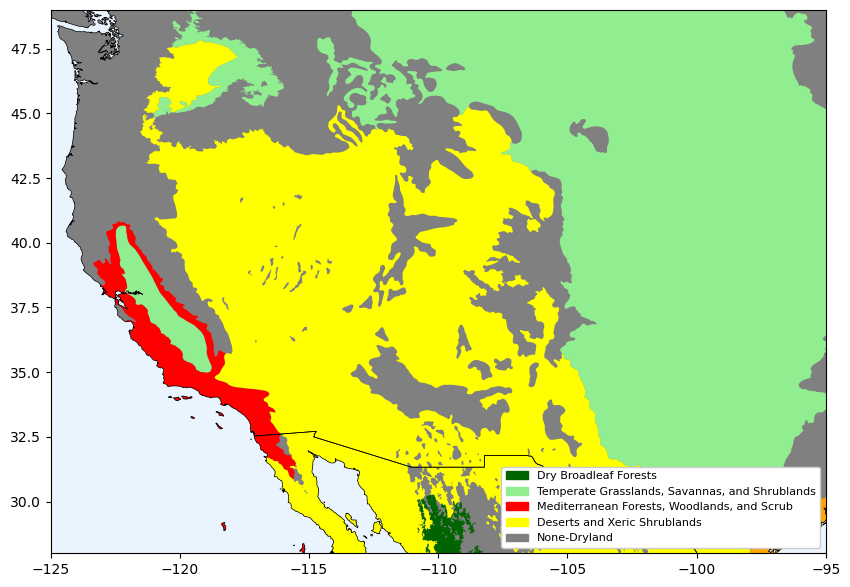

In [39]:
# Plot the world map
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('#EAF4FF')

#gdf_world_110m.plot(ax=ax, color='lightgrey', edgecolor='none')
#gdf_world_10m.plot(ax=ax, color='lightgrey', edgecolor='none')

# Set the title and remove axis
#ax.set_title('Global Dryland Biomes', fontsize=10)

# Set the title and remove axis
#ax.set_xlim([-160, 160])
#ax.set_ylim([-80, 80])
#ax.set_axis_off()

# usa only
ax.set_xlim([-125, -95])
ax.set_ylim([28, 49])

# southern africa only
#ax.set_xlim([12, 37])
#ax.set_ylim([-35, -20])

# chad sudan only
#ax.set_xlim([10, 35])
#ax.set_ylim([5, 25])

#ax.set_xticks([])
#ax.set_yticks([])
#ax.set_xticklabels([])
#ax.set_yticklabels([])

gdf_countries.plot(ax=ax, color= 'grey', edgecolor='none',linewidth=0.5)

gdf_biomeA.plot(ax=ax, color='darkgreen', edgecolor='none')
gdf_biomeB.plot(ax=ax, color='orange', edgecolor='none')
gdf_biomeC.plot(ax=ax, color='lightgreen', edgecolor='none')
gdf_biomeD.plot(ax=ax, color='pink', edgecolor='none')
gdf_biomeE.plot(ax=ax, color='red', edgecolor='none')
gdf_biomeF.plot(ax=ax, color='yellow', edgecolor='none')

gdf_countries.plot(ax=ax, color= 'none', edgecolor='black',linewidth=0.5)

#gdf_biome2_glance.plot(ax=axes[1], color='blue', markersize=1)

# Create custom legend handles
darkgreen_pt = mpatches.Patch(color="darkgreen", label="Dry Broadleaf Forests")
orange_pt = mpatches.Patch(color="orange", label="Tropical Grasslands Savannas, and Shrublands")
lightgreen_pt = mpatches.Patch(color="lightgreen", label="Temperate Grasslands, Savannas, and Shrublands")
pink_pt = mpatches.Patch(color="pink", label="Montane Grasslands and Shrublands")
red_pt = mpatches.Patch(color="red", label="Mediterranean Forests, Woodlands, and Scrub")
yellow_pt = mpatches.Patch(color="yellow", label="Deserts and Xeric Shrublands")
grey_pt = mpatches.Patch(color="grey", label="None-Dryland")

ax.legend(handles=[darkgreen_pt, lightgreen_pt, red_pt, yellow_pt,grey_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )
#ax.legend(handles=[orange_pt, pink_pt, red_pt, yellow_pt, grey_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )
#ax.legend(handles=[orange_pt, yellow_pt, grey_pt], loc="lower right",fontsize=8,frameon=True,framealpha=1.0 )

plt.savefig("output_plot.jpg", dpi=300, bbox_inches="tight")
plt.show()

## Concatentate all Patches and Labels and Samples (All Biomes)

In [ ]:
# load patch data
patches1 = np.load('../Inference_Patches/biomeC1_random_patches_2021.npy')
patches2 = np.load('../Inference_Patches/biomeC2_random_patches_2021.npy')
patches_all = np.concatenate((patches1,patches2),axis=0)
np.save('../Patch_data/biomeA_random_patches.npy', patches_all)
patches_load = np.load('../Patch_data/biomeA_random_patches.npy')
patches_load.shape